In [2]:
%pip install tensorflow==2.22.0rc0

   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/384.1 MB 1.4 MB/s eta 0:04:26
   ---------------------------------------- 1.0/384.1 MB 1.4 MB/s eta 0:04:34
   ---------------------------------------- 1.3/384.1 MB 1.4 MB/s eta 0:04:32
   ---------------------------------------- 1.6/384.1 MB 1.5 MB/s eta 0:04:23
   ---------------------------------------- 2.1/384.1 MB 1.5 MB/s eta 0:04:14
   ---------------------------------------- 2.4/384.1 MB 1.5 MB/s eta 0:04:15
   ---------------------------------------- 2.6/384.1 MB 1.5 MB/s eta 0:04:09
   ---------------------------------------- 3.1/384.1 MB 1.6 MB/s eta 0:04:00
   ---------------------------------------- 3.7/384.1 MB 1.7 MB/s eta 0:03:50
   ---------------------------------------- 4.2/384.1 MB 1.7 MB/s eta 0:03:43
   ----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [3]:
import tensorflow as tf
from tensorflow import keras

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc0


In [4]:
# Carregar o dataset
fashion_mnist = keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

print()
print(train_images.shape)
print(len(train_labels))
print(train_labels)
print(test_images.shape)
print(len(test_labels))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

(60000, 28, 28)
60000
[9 0 0 ... 3 0 5]
(10000, 28, 28)
10000


In [6]:
# Salva as classes
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

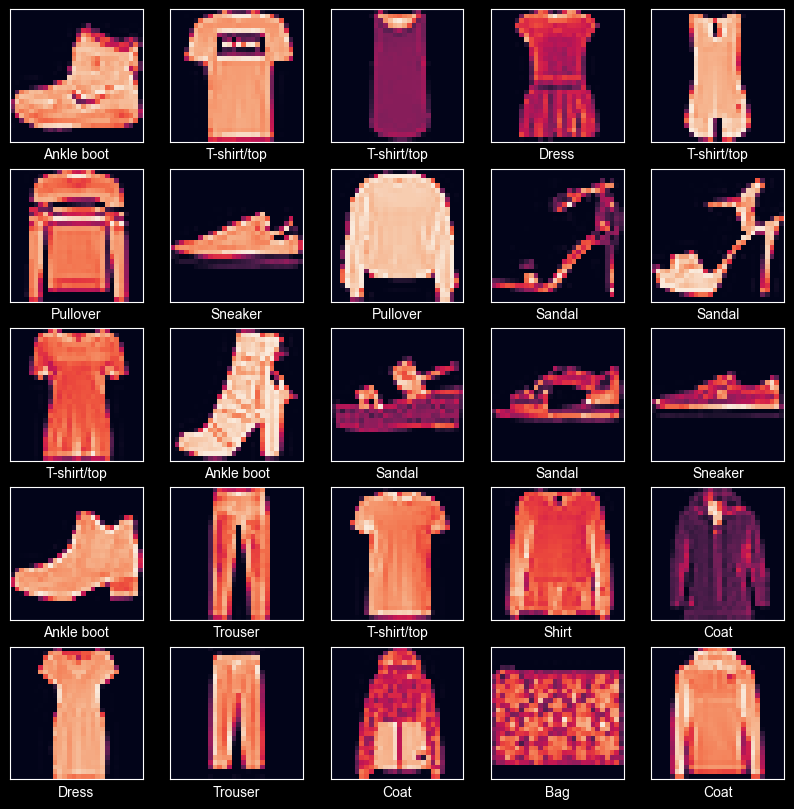

In [7]:
# Exibir algumas imagens
plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5, 5, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(train_images[i])
  plt.xlabel(class_names[train_labels[i]])
plt.show()

In [8]:
# Normalizar os dados
train_images = train_images / 255.0
test_images = test_images / 255.0

In [9]:
# Torna as imagens lineares - Entrada para o Sklearn
def flatten(f):
  flat_list = [item for sublist in f for item in sublist]
  return flat_list

# Criar as features para uso do sklearn
train_images_features = [ flatten(image) for image in train_images ]
test_images_features = [ flatten(image) for image in test_images ]

In [10]:
# Arquitetura da rede
ann = MLPClassifier(hidden_layer_sizes=(128,),
                    activation="relu",
                    solver="adam",
                    learning_rate_init=0.001,
                    max_iter=10,
                    random_state=42,
                    verbose=True)

# Treinamento do modelo
ann.fit(train_images_features, train_labels)

# Predição e avaliação
preds = ann.predict(test_images_features)
print("Acurácia: ", accuracy_score(test_labels, preds))

Iteration 1, loss = 0.58955020
Iteration 2, loss = 0.42246219
Iteration 3, loss = 0.38222630
Iteration 4, loss = 0.35730082
Iteration 5, loss = 0.33768557
Iteration 6, loss = 0.31672571
Iteration 7, loss = 0.30669854
Iteration 8, loss = 0.29504787
Iteration 9, loss = 0.28465529
Iteration 10, loss = 0.27497446


C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


Acurácia:  0.8811


In [12]:
# Definição da semente de aleatoriedade
tf.random.set_seed(42)

# Define o modelo
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

# Compilar o modelo
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [13]:
# O que tem neste modelo?
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Treinamento do modelo
model.fit(train_images, train_labels, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8235 - loss: 0.4991
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8634 - loss: 0.3768
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8768 - loss: 0.3369
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8850 - loss: 0.3128
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8923 - loss: 0.2936
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8969 - loss: 0.2789
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9012 - loss: 0.2668
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9056 - loss: 0.2544
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9090 - loss: 0.2447
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9123 - loss: 0.2356


In [15]:
# Avaliação do modelo
test_loss, test_acc = model.evaluate(test_images, test_labels)

print("Test loss: ", test_loss)
print("Test  ACC: ", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8810 - loss: 0.3467
Test loss:  0.3467095196247101
Test  ACC:  0.8809999823570251
